# *Prediksi Jumlah Penyewaan Sepeda Berdasarkan Faktor Waktu dan Cuaca Menggunakan Algoritma Regresi.*

- NAMA : ANLE DANIEL PRATAMA
- KELAS : 05TPLP023
- NIM :241011400896

## *Algoritma, transformasi, modeling, dan metrik yang digunakan*
- Jenis Machine Learning : Supervised Learning
- Jenis masalah : Regresi
- Algoritma : 1. Linear Regression, 2. Random Forest Regressor
- Transformasi data : Pemilihan fitur dan target, dan Pengkodean kategori sudah tersedia
- Pembagian data :Train-test split berdasarkan waktu
- Metrik evaluasi : MAE, RMSE, R²
- Development : Streamlit 

## *1. Data Loading*

Data Loading adalah proses mengambil dataset dan memasukkannya ke dalam Python agar bisa diolah. Dataset yang kita gunakan adalah `hour.csv` dari Bike Sharing Dataset. Setiap baris mewakili catatan penyewaan sepeda per jam.

pada langkah awal ini saya mengimport file menggunakan library pandas untuk mengolah data berbentuk tabel, lalu membaca file `.csv` dan di simpan padda variabel `df`. lalu `df.shape` digunakan untuk menampilkan jumlah baris dan kolom pada file `hour.csv`, dan `df.head` untuk menampilkan lima baris pertama supaya kita bisa melihat bentuk dan isi data.

In [2]:
import pandas as pd

df = pd.read_csv("hour.csv")

print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## *2. Data Cleaning*

Data Cleaning adalah proses memeriksa apakah dataset memiliki masalah, misalnya nilai kosong, data duplikat, atau tipe data yang tidak sesuai.

pada tahap ini saya mulai dengan `df.info` dima code ini untuk menampilkan nama kolom, jumlah data yang terisi,tipe data, dan penggunakaan memory. `df.isnull` untuk memeriksa nilai yang kosong dan `.sum` untuk menghitung. lalu `df.duplicated` dan `.sum` untuk menghitung data yang jumlah data yang sama atau duplikat. dan  `df.drop_duplicates` untuk menghapus data yang duplikat, tujuannya supaya data yang digunakan untuk analisis tidak memiliki masalah kualitas yang dapat mengganggu hasil pemodelan

In [3]:
df.info()

print("Nilai kosong:")
print(df.isnull().sum())

print("Jumlah duplikat:", df.duplicated().sum())

df = df.drop_duplicates()

print("Ukuran setelah cleaning:", df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB
Nilai kosong:
instant       0
dteday        0
season        0
yr

## *3. EDA (Exploratory Data Analysis)*

EDA adalah proses memahami data melalui statistik dan visualisasi sebelum membangun model Machine Learning.
Dengan EDA, kita bisa melihat pola data, rentang nilai, dan distribusi jumlah penyewaan.

pada code di bawah `display(df.describe())` digunakan untuk menampilkan statistik numerik seperti;
- count: jumlah data yang diperiksa.
- mean: nilai rata-rata.
- std: standar deviasi atau gambaran penyebaran data.
- min: nilai terkecil.
- max: nilai terbesar.

In [4]:
display(df.describe())

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


## *3.1 Melihat distribusi jumlah penyewaan*

pada bagian ini melihat jumlah penyewaan yang paling sering muncul dan apakah distribusinya cenderung menumpuk pada nilai tertentu atau menyebar.

`import matplotlib.pyplot as plt` code ini digunakan untuk memanggil pustaka `matplotlib.pyplot` dimana code ini digunakan untuk membuat grafik. `plt.figure(figsize=(8, 5))` code ini untuk menentukan ukuran grafik yang akan di buat, `plt.hist(df["cnt"], bins=30)` code ini membuat histogram dari kolom cnt(count, dimana count itu jumlah atau total), dengan bins(jumlah kelompok, interval, atau "keranjang" (buckets)) 30 nilai. `title(), xlabel(), dan ylabel()` memberi judul dan label. dan yang terakhir `show()`untuk  menampilkan grafik.

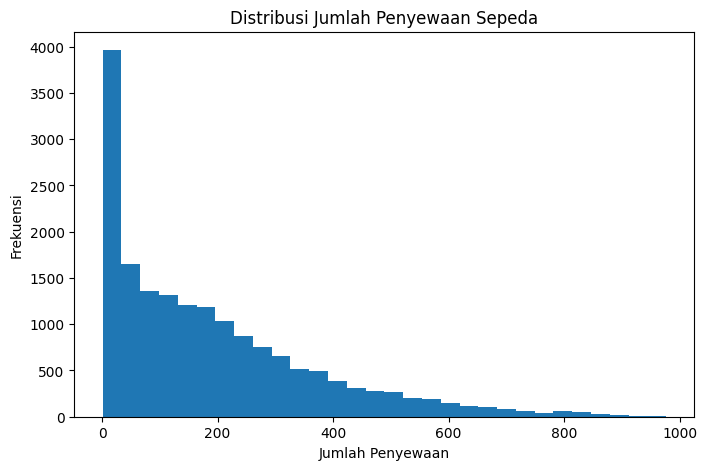

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["cnt"], bins=30)
plt.title("Distribusi Jumlah Penyewaan Sepeda")
plt.xlabel("Jumlah Penyewaan")
plt.ylabel("Frekuensi")
plt.show()

## *3.2 Melihat rata-rata penyewaan per jam*

pada bagian ini kita bisa tahu bawa rata-rata penyewaan sepeda per jam nya

pada code `df.groupby("hr")` digunakan untuk mengelompokkan data berdasarkan jamnya, lalu untuk code `["cnt"].mean()` untuk menghitung rata-rata penyewaan setiap jamnya. disini terdapat `rata_jam.index` nah itu digunaka sebagai sumbu X yaitu jam, sedangkan `rata_jam.values` sebagai sumbu Y yang dimana untuk rata-rata penyewaan. dan `marker="o"` untuk menampilkan titik pada setiap jam.

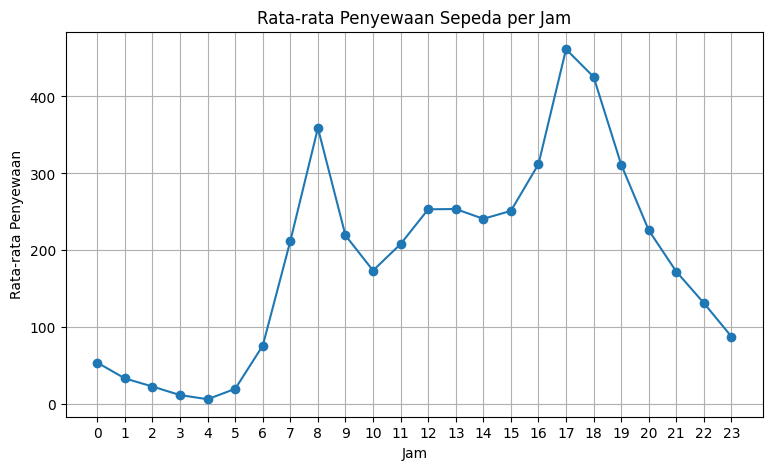

In [11]:
rata_jam = df.groupby("hr")["cnt"].mean()

plt.figure(figsize=(9, 5))
plt.plot(rata_jam.index, rata_jam.values, marker="o")
plt.title("Rata-rata Penyewaan Sepeda per Jam")
plt.xlabel("Jam")
plt.ylabel("Rata-rata Penyewaan")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

## *4. ExDA (Eksplorasi Data Lanjutan)*

ExDA di sini kita gunakan sebagai eksplorasi lanjutan setelah EDA. Fokusnya adalah melihat hubungan antara beberapa fitur dengan jumlah penyewaan.

## *4.1 Hubungan kondisi cuaca dengan penyewaan*

pada grafik ini membantu melihat apakah rata-rata penyewaan berbeda pada berbagai kondisi cuaca. Kode cuaca harus diartikan berdasarkan dokumentasi dataset, bukan diasumsikan sendiri.

- 1=Cuaca Cerah / Bagus
- 2=Cuaca Mendung / Gerimis Halus
- 3=Cuaca Buruk / Hujan / Salju Ringan
- 4=Cuaca Sangat Ekstrem


pada code `groupby("weathersit")` digunakan untuk mengelompokan data berdasarkan kode cuaca. lalu `mean()` menghitung rata-rata penyewaan pada setiap kondisi. dan `plot(kind="bar")` untuk membuat grafik batang.

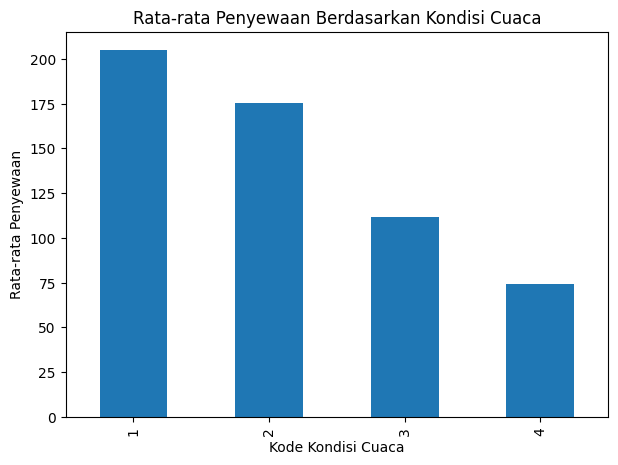

In [7]:
rata_cuaca = df.groupby("weathersit")["cnt"].mean()

plt.figure(figsize=(7, 5))
rata_cuaca.plot(kind="bar")
plt.title("Rata-rata Penyewaan Berdasarkan Kondisi Cuaca")
plt.xlabel("Kode Kondisi Cuaca")
plt.ylabel("Rata-rata Penyewaan")
plt.show()

## *4.2 Melihat korelasi antarfitur*

Pada bagian ini kita bisa melihat hubungan setiap nilai: korelasi mendekati 1 menunjukkan hubungan positif, mendekati -1 menunjukkan hubungan negatif, dan mendekati 0 menunjukkan tidak ada hubungan linear. 

tapi korelasi tidak membuktikan sebab-akibat. Selain itu, korelasi Pearson pada kode ini memperlakukan kode kategori sebagai angka, sehingga hasilnya perlu ditafsirkan dengan hati-hati.

pada code `df[kolom]` digunakan untuk mengambil kolom yang ingin diperiksa. code `.corr()` digunakan untuk menghitung korelasi antarvariabel numerik. code `imshow()`digunakan untuk menampilkan matriks korelasi sebagai peta warna. dan code `colorbar()` digunakan untuk menampilkan skala nilai korelasi.

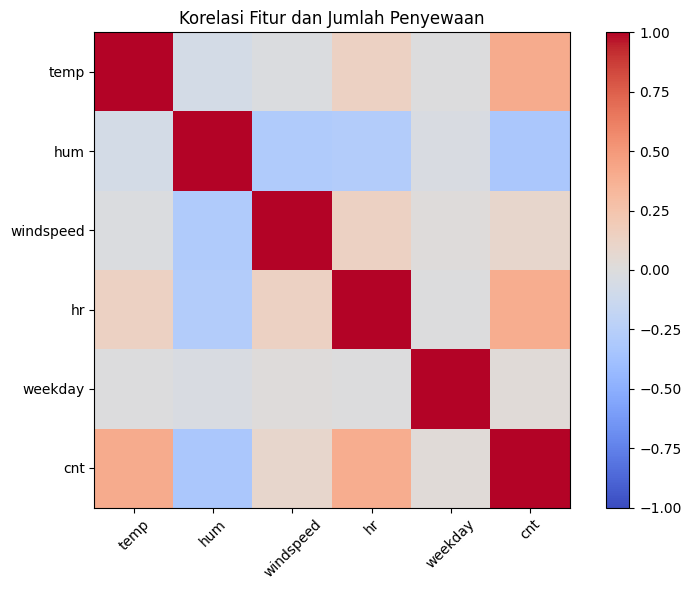

In [12]:
kolom = [
    "temp", "hum", "windspeed",
    "hr", "weekday", "cnt"
]

plt.figure(figsize=(8, 6))
plt.imshow(
    df[kolom].corr(),
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.colorbar()
plt.xticks(range(len(kolom)), kolom, rotation=45)
plt.yticks(range(len(kolom)), kolom)
plt.title("Korelasi Fitur dan Jumlah Penyewaan")
plt.tight_layout()
plt.show()

## *5. Data Preprocessing dan Transformasi*

Data Preprocessing adalah proses menyiapkan data agar bisa digunakan oleh algoritma Machine Learning.
Di proyek kita, langkah utamanya adalah memisahkan fitur (X) dan target (y), serta menentukan kolom yang digunakan untuk prediksi.

-  `fitur = [ "season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit", "temp", "atemp", "hum", "windspeed" ]` Kita memilih 12 kolom yang akan digunakan sebagai masukan model. Contohnya, jam, musim, suhu, dan kondisi cuaca. 
- `X = df[fitur]` code ini untuk membuat variabel `X` yang dimana X berisi fitur atau informasi yang digunakan model untuk memperkirakan jumlah penyewaan, lalu ada juga 
- `y = df["cnt"]`dimana code ini untuk membuat variabel `y` yang dimana y adalah target yang ingin diprediksi, yaitu jumlah penyewaan aktual. 
- `print("Jumlah fitur:", X.shape[1])` menghitung jumlah kolom fitur,dan 
- `print("Jumlah target:", y.shape[0])` menghitung jumlah baris target.


In [13]:
fitur = [
    "season", "yr", "mnth", "hr",
    "holiday", "weekday", "workingday",
    "weathersit", "temp", "atemp",
    "hum", "windspeed"
]

X = df[fitur]
y = df["cnt"]

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", y.shape[0])

Jumlah fitur: 12
Jumlah target: 17379


## *6. Data Splitting*

Data Splitting adalah proses membagi data menjadi data latih dan data uji.
- Data latih (training data): digunakan model untuk belajar.
- Data uji (testing data): digunakan untuk mengevaluasi model pada data yang tidak dipakai selama pelatihan.


### *Penjelasan*

Pada proyek ini, kita menggunakan pendekatan berdasarkan urutan waktu, yaitu data periode awal untuk pelatihan dan periode berikutnya untuk pengujian.

- `df = df.sort_values("dteday").reset_index(drop=True)` digunakan untuk mengurutkan data berdasarkan tanggal, dimana `sort_values("dteday")` mengurutkan data berdasarkan tanggal, sedangkan `reset_index(drop=True)` merapikan nomor indeks setelah pengurutan.
- `batas = int(len(df) * 0.8)` code ini digunakan untuk menentukan batas 80%. Misalnya, jika terdapat 17.379 baris, sekitar 13.903 baris pertama akan digunakan untuk pelatihan dan sisanya untuk pengujian.
- `X_train = X.iloc[:batas]` dan `X_test = X.iloc[batas:]` digunakan untuk membagi fitur dimana `X_train` mengambil fitur dari awal sampai batas pelatihan, dan `X_test` mengambil fitur setelah batas tersebut.
- `y_train = y.iloc[:batas]` dan `y_test = y.iloc[batas:]` digunakan untuk pembagian target, dimana Pembagian target itu  harus sesuai dengan pembagian fitur agar setiap baris masukan memiliki target yang tepat.

##### *Kenapa tidak dibagi secara acak?*
Karena data penyewaan memiliki urutan waktu. Kita ingin menguji model pada periode yang lebih baru daripada periode yang digunakan untuk belajar.

In [14]:
df = df.sort_values("dteday").reset_index(drop=True)

X = df[fitur]
y = df["cnt"]

batas = int(len(df) * 0.8)

X_train = X.iloc[:batas]
X_test = X.iloc[batas:]

y_train = y.iloc[:batas]
y_test = y.iloc[batas:]

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)

Data latih: (13903, 12)
Data uji: (3476, 12)


## *7. Modeling (Membangun Model)*

Modeling adalah tahap ketika algoritma Machine Learning belajar dari data latih untuk membentuk pola yang dapat digunakan dalam prediksi.

Pada proyek ini, saya membandingkan dua algoritma regresi yaitu;
1. Linear Regression
Algoritma yang mencoba mempelajari hubungan linear antara fitur masukan dan target.
Contoh sederhana: model mempelajari bagaimana perubahan jam, suhu, atau faktor lain berkaitan dengan perubahan jumlah penyewaan.

2. Random Forest Regressor
Algoritma yang membangun banyak pohon keputusan dan menggabungkan hasilnya untuk menghasilkan prediksi.



#### *penjelasan*

- `from sklearn.linear_model import LinearRegression` dan `from sklearn.ensemble import RandomForestRegressor` code ini digunakan untuk mengimpor algoritma dari skylearn
- `model_lr = LinearRegression()` code ini digunakan untuk membuat model Linear Regression, dimana baris ini membuat objek model regresi linear. Model belum belajar dari data pada tahap ini.
- `model_rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)` code ini digunakan untuk membuat model Random Forest, dimana dalam code tersebut terdapat 1. `n_estimators=100:` menggunakan 100 pohon keputusan. 2. `random_state=42:` membuat proses acak tertentu lebih konsisten ketika kode dijalankan ulang. 3. `n_jobs=-1:` menggunakan seluruh inti prosesor yang tersedia untuk mempercepat proses yang mendukung paralelisasi.
- `model_lr.fit(X_train, y_train)` dan `model_rf.fit(X_train, y_train)` code ini digunakan untuk melatih kedua model. dan di dalam model juga terdapat `fit()`, dimana `fit()` tersebut adalah proses belajar. Model mempelajari hubungan antara fitur X dan target y dari data latih.
- `pred_lr = model_lr.predict(X_test)` dan `pred_rf = model_rf.predict(X_test)` code ini menghasilkan prediksi, dan pada code tersebut `predict()` yang dimana `predict()` menggunakan model yang sudah dilatih untuk memperkirakan jumlah penyewaan pada data uji.

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

model_lr = LinearRegression()

model_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model_lr.fit(X_train, y_train)
model_rf.fit(X_train, y_train)

pred_lr = model_lr.predict(X_test)
pred_rf = model_rf.predict(X_test)

print("Model berhasil dilatih.")

Model berhasil dilatih.


## *8. Evaluasi Model*

setelah model menghasilkan prediksi, kita perlu memeriksa seberapa jauh hasil prediksi berbeda dari jumlah penyewaan yang sebenarnya.
Kita menggunakan tiga metrik evaluasi:
- MAE (Mean Absolute Error)
- RMSE (Root Mean Squared Error)
- R² Score (Coefficient of Determination)

## *penjelasan*

- `from sklearn.metrics import mean_absolute_error` dan `from sklearn.metrics import mean_squared_error, r2_score` mengimpor metrik evaluasi
- `def evaluasi(nama, aktual, prediksi):` code ini digunakan untuk membuat fungsi evaluasi. di Fungsi tersebut menerima tiga masukan, yaitu: `nama`: nama model, `aktual`: nilai jumlah penyewaan yang sebenarnya. dan `prediksi`: nilai yang diperkirakan model.
- `mae = mean_absolute_error(aktual, prediksi)` code ini diguanakan untuk menghitung MAE, MAE itu untuk menghitung rata-rata selisih absolut antara nilai aktual dan prediksi.
Contohnya, MAE sebesar 20 berarti rata-rata kesalahan absolut prediksi adalah sekitar 20 penyewaan per observasi pada data uji.
- `rmse = np.sqrt(mean_squared_error(aktual, prediksi))` code ini digunakan untuk menghitung RMSE, RMSE itu untuk menghitung akar dari rata-rata kuadrat kesalahan. Karena kesalahan dikuadratkan terlebih dahulu, kesalahan yang besar mendapat penalti lebih tinggi.
- `r2 = r2_score(aktual, prediksi)`code ini digunakan untuk menghitung R², R² digunakan untuk mengukur seberapa baik prediksi model menjelaskan variasi target pada data uji, dibandingkan dengan prediksi sederhana menggunakan rata-rata target.
Nilai R² dapat bernilai negatif jika model lebih buruk daripada pembanding tersebut.

In [16]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

def evaluasi(nama, aktual, prediksi):
    mae = mean_absolute_error(aktual, prediksi)
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))
    r2 = r2_score(aktual, prediksi)

    return {
        "Model": nama,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

hasil = pd.DataFrame([
    evaluasi("Linear Regression", y_test, pred_lr),
    evaluasi("Random Forest", y_test, pred_rf)
])

display(hasil)

,Model,MAE,RMSE,R2
0,Linear Regression,138.342401,183.102449,0.308955
1,Random Forest,45.025674,70.270456,0.898220


## *9. Membandingkan nilai aktual dengan prediksi*
Evaluasi dengan angka saja terkadang sulit dipahami. Karena itu, kita bisa melihat beberapa contoh prediksi dan membandingkannya dengan nilai aktual.

disini juga saya akan membandingkan 3 metrik evaluasi

## *9.1 Membandingkan nilai aktual dengan prediksi MAE*

- `hasil.loc[1, "MAE"]` mengambil nilai MAE model Random Forest.
- `hasil.loc[0, "MAE"]` mengambil nilai MAE Linear Regression.
- Model dengan MAE lebih kecil dipilih sebagai model terbaik untuk percobaan awal ini.
- `predict(X_test)` menghasilkan prediksi menggunakan model yang terpilih.
- `head(10)` menampilkan sepuluh contoh hasil perbandingan.

In [17]:
model_terbaik = (
    model_rf if hasil.loc[1, "MAE"] < hasil.loc[0, "MAE"]
    else model_lr
)

pred_terbaik = model_terbaik.predict(X_test)

perbandingan = pd.DataFrame({
    "Aktual": y_test.values,
    "Prediksi": pred_terbaik
})

display(perbandingan.head(10))

,Aktual,Prediksi
0,250,202.56
1,47,47.94
2,18,17.24
3,13,9.48
4,6,5.10
5,9,6.06
6,214,235.57
7,179,161.15
8,502,500.66
9,705,702.93


## *9.3 Membandingkan nilai aktual dengan prediksi RMSE*

In [18]:
model_terbaik = (
    model_rf if hasil.loc[1, "RMSE"] < hasil.loc[0, "RMSE"]
    else model_lr
)

pred_terbaik = model_terbaik.predict(X_test)

perbandingan = pd.DataFrame({
    "Aktual": y_test.values,
    "Prediksi": pred_terbaik
})

display(perbandingan.head(10))

,Aktual,Prediksi
0,250,202.56
1,47,47.94
2,18,17.24
3,13,9.48
4,6,5.10
5,9,6.06
6,214,235.57
7,179,161.15
8,502,500.66
9,705,702.93


## *9.3 Membandingkan nilai aktual dengan prediksi R2*

In [19]:
model_terbaik = (
    model_rf if hasil.loc[1, "R2"] < hasil.loc[0, "R2"]
    else model_lr
)

pred_terbaik = model_terbaik.predict(X_test)

perbandingan = pd.DataFrame({
    "Aktual": y_test.values,
    "Prediksi": pred_terbaik
})

display(perbandingan.head(10))

,Aktual,Prediksi
0,250,271.410431
1,47,172.912816
2,18,178.159996
3,13,185.406828
4,6,188.155279
5,9,193.451584
6,214,292.036156
7,179,219.549061
8,502,233.223455
9,705,244.920732


## *9.4 Grafik aktual dan prediksi*

Setiap titik menunjukkan satu observasi. Jika prediksi semakin dekat dengan nilai aktual, titik-titik akan semakin dekat dengan garis diagonal imajiner dari kiri bawah ke kanan atas.

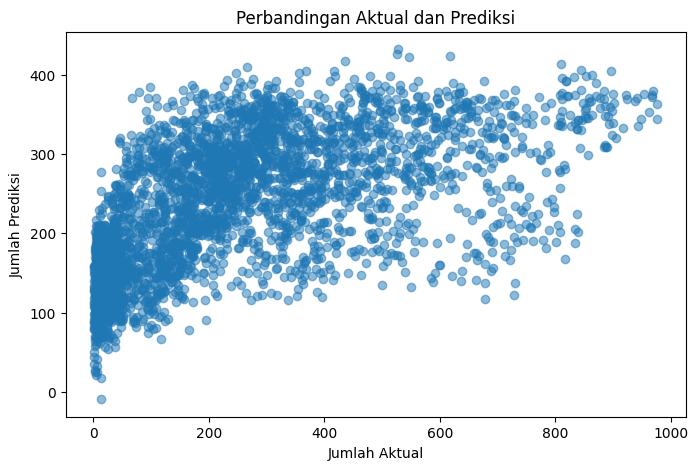

In [20]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, pred_terbaik, alpha=0.5)
plt.xlabel("Jumlah Aktual")
plt.ylabel("Jumlah Prediksi")
plt.title("Perbandingan Aktual dan Prediksi")
plt.show()

## *10. Development (Mengembangkan Model Menjadi Aplikasi)*

Development adalah tahap mengembangkan hasil penelitian menjadi sesuatu yang bisa digunakan, bukan hanya kode yang berjalan di notebook.
Dalam proyek ini, model Machine Learning akan dibuat menjadi aplikasi web menggunakan Streamlit. Pengguna bisa memasukkan informasi waktu dan cuaca, lalu aplikasi menampilkan perkiraan jumlah penyewaan sepeda.

## *10.1 Menyimpan model yang sudah dilatih*
Kita tidak perlu melatih model dari awal setiap kali aplikasi dibuka. Model yang sudah dilatih bisa disimpan menggunakan joblib

- `import joblib` code ini digunakan untuk memanggil pustaka untuk menyimpan dan membaca objek Python.
- `joblib.dump()` code ini digunakan untuk menyimpan model ke file.
- `model_bike.pkl` code ini digunakan untuk berisi model yang sudah dilatih.
- `fitur_bike.pkl` code ini digunakan untuk berisi daftar nama fitur sesuai urutan yang digunakan model.

In [21]:
import joblib

joblib.dump(model_terbaik, "model_bike.pkl")
joblib.dump(fitur, "fitur_bike.pkl")

print("Model dan fitur berhasil disimpan.")

Model dan fitur berhasil disimpan.


## *10.2 Membuat aplikasi dengan Streamlit*

code aplikasi ada di file app.py